# Create Danionella Dataset — Frame Export for Labeling

This notebook exports frames from experiment videos to image files for manual labeling (e.g. in [Roboflow](https://roboflow.com)). The resulting images are used to build the training set for the YOLOv8 fish detector.

**Dependencies:** The full workflow uses the `utilities` package from [`../acquisition/utilities`](../acquisition/utilities) (preprocessing, tracking, reading) and the experiment directory layout written by the acquisition notebook. If you only need to **train** on existing data, use `train_yolov8.ipynb` and the bundled `dataset/`.

---

## 1. Libraries and setup

In [1]:
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter

In [2]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'    

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import warnings
warnings.filterwarnings("ignore")

In [5]:
import numpy as np
import cv2

In [6]:
import matplotlib.pyplot as plt
from scipy.ndimage import rotate

import time
import datetime
import math

from numba import njit

import imageio.v2 as imageio

from math import sqrt
from skimage import data
from skimage.feature import blob_dog, blob_log, blob_doh
from skimage.color import rgb2gray

import matplotlib.pyplot as plt
from skimage.transform import downscale_local_mean
from scipy.ndimage import gaussian_filter

from scipy import signal
import scipy.ndimage
from scipy.stats import skew
from scipy import stats

from time import sleep
from tqdm.notebook import tqdm

from matplotlib import animation
from matplotlib.patches import Rectangle, Circle
from PIL import Image
import re

from ipywidgets import interact,IntSlider

import matplotlib.patches as patches

In [7]:
import scipy as sc
import scipy.signal
from scipy.signal import find_peaks
from scipy import ndimage

In [8]:
#import SimpleITK as sitk

In [9]:
import matplotlib.patches as patches

In [10]:
from skimage import data, color
from skimage.transform import rescale, resize, downscale_local_mean
from skimage import io, draw
from skimage.draw import disk
from skimage.registration import phase_cross_correlation

## 2. Acquisition utilities (required for full pipeline)

Imports from `../acquisition/utilities` for loading experiments and tracking. Omit or replace if you are only exporting from your own video arrays.

In [11]:
# Utilities from the acquisition module (this repo)
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', 'acquisition')))
from utilities.preprocessing import preprocess_im, bw_image, noise_removal, area_contours, residual_edge_removal
from utilities.tracking import centroid, centroid2, get_ellipse, img_draw_ellipse
from utilities.live_kinematic_parameters import Fish_live
from utilities.saving import saveList, loadList
from utilities.reading import readingMovie, sorted_alphanumeric
from skimage.io import imsave

In [12]:
def show_img(image):
    plt.figure()
    plt.imshow(image,origin='lower',cmap='gist_gray')
    plt.show()

In [13]:
@njit
def next_segment(im,x0,y0,dx,dy,r,segment_length,scalar_product_threshold=0.5): 
    r2=r**2
    y_max,x_max=im.shape
    xs=min(max(int(round(x0+dx-r)),0),x_max)
    xl=min(max(int(round(x0+dx+r)),0),x_max)
    ys=min(max(int(round(y0+dy-r)),0),y_max)
    yl=min(max(int(round(y0+dy+r)),0),y_max)
    if xs==xl or ys==yl:
        return np.nan,np.nan,np.nan,np.nan
    acc=0.0
    acc_x=0.0
    acc_y=0.0
    for x in range(xs,xl):
        for y in range(ys,yl):
            lx=(x0+dx-x)**2
            ly=(y0+dy-y)**2
            if lx+ly<=r2:
                acc_x+=x*im[y,x]
                acc_y+=y*im[y,x]
                acc+=im[y,x]
    if acc==0:
        return np.nan,np.nan,np.nan,np.nan
    dx_new=acc_x/acc-x0
    dy_new=acc_y/acc-y0
    norm=np.sqrt(dx_new**2+dy_new**2)
    if norm==0:
        return np.nan,np.nan,np.nan,np.nan
    dx_new=dx_new/norm*segment_length
    dy_new=dy_new/norm*segment_length
    if (dx*dx_new+dy*dy_new)/segment_length**2<scalar_product_threshold:
        return np.nan,np.nan,np.nan,np.nan
    return x0+dx_new,y0+dy_new,dx_new,dy_new

In [14]:
def tracking_tail(x, y, orientation, img_bw, n_segments, window_radius, tail_length, segment_length):
    """Function that run the online tracking for the fish position and tail points.
  
    Parameters
    ----------
    x, y: real time fish position, from 'fish_position'
    orientation: real time orientation, from 'get_ellipse'
    n_segments : number of segments in the curve approximating the tail
    window_radius : radius of the ROI in which control the min/max pixel in order to go ahead along the tail 
    tail_length : evaluated time by time
    segment_length : tail_lenght / n_segments
    
    Returns
    ----------
    tail_points : segmented tail
    """
    tail_points=np.full((n_segments+1,2),np.nan)
    
    # tail tracking if and only if: an object is detected (~np.isnan(E.x)) 
    if ~np.isnan(x) and ~np.isnan(orientation):

        initial_x, initial_y = x , y
        theta_tail=orientation

        initial_dx =  segment_length*np.cos(theta_tail) 
        initial_dy =  segment_length*np.sin(theta_tail)

        tail_points[0]=[initial_x,initial_y]

        for s in range(1,n_segments+1):

            initial_x, initial_y, initial_dx, initial_dy = next_segment(img_bw, initial_x, initial_y, initial_dx, initial_dy, window_radius, segment_length)

            if np.isnan(initial_x):
                break
                
            tail_points[s]=[initial_x, initial_y]
        
    return tail_points

## 3. Paths and experiment selection

Set the experiment root and identifiers. Use paths appropriate for your machine.

In [15]:
# Experiment data root: set to your folder (e.g. experiment archive or network drive)
path = os.environ.get("EXPERIMENT_DATA_ROOT", os.path.join(os.getcwd(), "data"))

In [289]:
date = '27Jul23' 
age = '11' 

In [290]:
dir_experiment_day = os.path.join(path,'fs_'+ str(age)+'dpf_'+ str(date))
if not os.path.exists(os.path.join(path,dir_experiment_day)):
    print('ERROR: this folder does not exist.')
else:
    print('dir_experiment_day exists properly, path: ', dir_experiment_day)
    for file in os.listdir(dir_experiment_day):
        print(file)
path_calib = dir_experiment_day

dir_experiment_day exists properly, path:  E:\data\fs_11dpf_27Jul23
9dpf_dc.bmp
fish_1
fish_2
fish_3
mask.npy


In [291]:
fish_number = '3'

In [292]:
dir_experiment_fish = os.path.join(dir_experiment_day,'fish_'+ str(fish_number))
if not os.path.exists(os.path.join(path,dir_experiment_fish)):
    print('ERROR: this folder does not exist.')
else:
    print('dir_experiment_fish exists properly, path: ', dir_experiment_fish)

dir_experiment_fish exists properly, path:  E:\data\fs_11dpf_27Jul23\fish_3


In [311]:
for file in os.listdir(dir_experiment_fish):
    print(file)
run = input("Enter run: ")

array_stones.npy
for_plotting.npy
run1
run2
run3
run4
run5


Enter run:  run1


## Importing...

### parameters

In [312]:
for file in os.listdir(dir_experiment_fish):  
    if file[0]=='r':
        path_data = os.path.join(dir_experiment_fish,run,'data') 
        path_movie = os.path.join(dir_experiment_fish,run,'movie') 
        
dir_experiment_run = os.path.join(dir_experiment_fish,run)
for file in os.listdir(dir_experiment_run):  
    print(file)

array_stones_2.npy
data
for_plotting.npy
movie


In [313]:
#calibration
mm_per_pix = exp_parameters[1]

#image processing
gaussian_sigma = 1
downsampling = 2

#stones image
stones_pos = exp_parameters[3]
stones_size = exp_parameters[5]
agar_abs = exp_parameters[7]
xA_abs,yA_abs=agar_abs[0],agar_abs[1]
xB_abs,yB_abs=agar_abs[2],agar_abs[3]
xC_abs,yC_abs=agar_abs[4],agar_abs[5]
xD_abs,yD_abs=agar_abs[6],agar_abs[7]

#projector 
proj_width=84
x_center_motor=164.0
y_center_motor=236.0


### data

In [314]:
for file in os.listdir(path_data):
    print(file)
    cameratimes=np.load(os.path.join(path_data, 'cameratimes.npy'))
    cameratimestamp=np.load(os.path.join(path_data, 'cameratimestamp.npy'))
     
    pos=np.load(os.path.join(path_data, 'centroid_tot.npy'))
    
    motorpositions=np.load(os.path.join(path_data, 'motorpositions.npy'))
    motortimes=np.load(os.path.join(path_data, 'motortimes.npy'))

    trackingtimes=np.load(os.path.join(path_data, 'trackingtimes.npy'))

cameratimes.npy
cameratimestamp.npy
centroid_tot.npy
motorpositions.npy
motortimes.npy
trackingtimes.npy


In [315]:
## ONLY 3VIDEO
n_video=0
frame_per_video=[]
for file in sorted_alphanumeric(os.listdir(path_movie)):
    print(file)
    if file[6]=='0':
        myVideo=np.load(os.path.join(path_movie,file) , allow_pickle=True)
        print(myVideo.shape)
      
 

movie_0.npy
(251, 251, 15000)
movie_1.npy


In [316]:
img_ref=myVideo[:,:,0]
xROIcenter=img_ref.shape[0]/2
yROIcenter=img_ref.shape[1]/2
w_img=img_ref.shape[0]
h_img=img_ref.shape[1]
print(xROIcenter,yROIcenter,w_img,h_img)

125.5 125.5 251 251


### IMP

In [317]:
fish_x=(pos[:,0]-xROIcenter)*mm_per_pix
fish_y=(pos[:,1]-yROIcenter)*mm_per_pix
print('mm_per_pix',mm_per_pix)

mm_per_pix 0.05035840904307598


In [318]:
%matplotlib inline
def slider_movie(frame):
    plt.close()
    plt.figure(figsize=(5,2),dpi=150)
    plt.imshow(myVideo[:,:,frame],origin='lower')
    plt.show()
    
interact(slider_movie,frame=IntSlider(value=480,min=0,max=myVideo[:,:,:].shape[2]-1,step=1));

interactive(children=(IntSlider(value=480, description='frame', max=14999), Output()), _dom_classes=('widget-i…

## 4. Export frames to images

Choose a frame, then save it (and optionally more) as JPEGs for uploading to Roboflow.

In [319]:
# Output folder for exported frames (relative to repo root)
path_image = os.path.join(os.getcwd(), "images_Roboflow")
os.makedirs(path_image, exist_ok=True)

In [ ]:
# Run once before exporting the first image
idd = 0

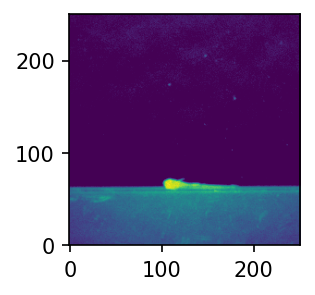

In [330]:
frame=11426
plt.close()
plt.figure(figsize=(5,2),dpi=150)
plt.imshow(rotate(myVideo[:,:,frame],270),origin='lower')
plt.show()


In [331]:
# Increment counter (initialise idd = 0 before first export)
idd = idd + 1
# Rotate frame to desired orientation and save as JPEG for Roboflow
image_data = rotate(myVideo[:, :, frame], 270)
image = Image.fromarray(image_data)
image.save(os.path.join(path_image, "image_" + str(idd) + ".jpg"), "JPEG")